# 03 — Vendor KPIs

All KPIs are defined once, in SQL, as views in `procurement_db` (`sql/04_kpi_views.sql`). This notebook:

1. reads the headline KPIs from `kpi_summary`;
2. **recomputes every KPI independently in pandas** from the base tables and checks that both agree;
3. runs a stock reconciliation check;
4. looks at the vendor scorecard, monthly trends and categories;
5. exports the KPI tables to `reports/kpi/` (the dashboard also reads them straight from the database).

| # | KPI | Why it matters |
|---|---|---|
| 1–2 | On-time delivery (OTD), on-time in full (OTIF) | Late or short deliveries stop production |
| 3–5 | Average delay, lead time, lead-time variability | Planning buffers and safety stock depend on these |
| 6 | Fill rate | Short shipments |
| 7–8 | Rejection rate, receipts with rejections | Supplier quality |
| 9 | Price variance vs standard cost | Cost control (standards are stale, see EDA) |
| 10–14 | Spend, top-vendor shares, HHI, vendors for 80% of spend | Vendor dependency |
| 15 | Single-source items | Supply risk |
| 16–19 | Bulk-buy savings, bulk discount, urgent premium, urgent orders | Buying behaviour |
| 20–23 | Excess inventory, turnover, days on hand | Working capital tied up in stock |
| 24 | Overdue open PO lines | Current backlog |

Key definitions follow the EDA decisions: overdue undelivered lines count as late (right-censoring), price is
benchmarked against the market (median price of the same item, quarter and order type), bulk/urgent prices are compared
like-for-like with regular orders, and excess stock = stock above 6 months of cover.

In [1]:
import sys
sys.path.append("../src")

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
from sqlalchemy import text

from db import get_engine
from utils import REPORTS_DIR
from viz_style import INK_2, MUTED, SERIES, apply_style, save, subtitle

apply_style()
engine = get_engine()
KPI_DIR = REPORTS_DIR / "kpi"
KPI_DIR.mkdir(exist_ok=True)


def q(sql, dates=()):
    df = pd.read_sql(text(sql), engine)
    for c in dates:
        df[c] = pd.to_datetime(df[c])
    return df


pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_colwidth", 120)

## 1. Headline KPIs (from SQL)

In [2]:
summary = q("SELECT * FROM kpi_summary ORDER BY kpi_no")
summary["value"] = summary["value"].astype(float)
summary[["kpi_no", "kpi", "value", "unit"]]

,kpi_no,kpi,value,unit
0,1,On-time delivery (OTD),70.98,%
1,2,On-time in full (OTIF),62.55,%
2,3,Average delay of late deliveries,10.55,days
3,4,Average lead time,12.33,days
4,5,Lead-time variability,8.72,days
5,6,Fill rate,98.88,%
6,7,Rejection rate (quantity),0.35,%
7,8,Receipts with rejections,4.52,%
8,9,Purchase price variance vs standard cost,4.21,%
9,10,Total spend,"1,540.04",₹ crore


## 2. Independent check: recompute every KPI in pandas

The pandas code below works from the **base tables only** (no views), so it is a genuine second implementation.
If a SQL view had a logic bug (a wrong join, a NULL handled differently), the two numbers would disagree.

In [3]:
po = q("SELECT po_id, line_no, order_date, vendor_id, item_id, quantity, unit_price, order_type, promised_date FROM purchase_orders",
       dates=["order_date", "promised_date"])
dl = q("SELECT po_id, line_no, received_date, qty_received, qty_rejected FROM deliveries", dates=["received_date"])
items = q("SELECT item_id, standard_price FROM items")
sales = q("SELECT item_id, month, qty_sold FROM sales", dates=["month"])
inv = q("SELECT item_id, snapshot_date, qty_on_hand FROM inventory", dates=["snapshot_date"])
po["unit_price"] = po.unit_price.astype(float)
items["standard_price"] = items.standard_price.astype(float)
po["line_value"] = po.quantity * po.unit_price
cutoff = po.order_date.max()

# Receipts per PO line
d = dl.merge(po[["po_id", "line_no", "promised_date"]], on=["po_id", "line_no"])
d["by_promise"] = d.qty_received.where(d.received_date <= d.promised_date, 0)
d["inspected"] = d.qty_received.where(d.qty_rejected.notna())
d["rcpt_rej"] = (d.qty_rejected > 0).astype(int)
d["rcpt_insp"] = d.qty_rejected.notna().astype(int)
r = d.groupby(["po_id", "line_no"]).agg(first=("received_date", "min"), qty_rcv=("qty_received", "sum"),
                                         by_promise=("by_promise", "sum"), rej=("qty_rejected", "sum"),
                                         insp=("inspected", "sum"), rcpt_rej=("rcpt_rej", "sum"),
                                         rcpt_insp=("rcpt_insp", "sum")).reset_index()
L = po.merge(items, on="item_id").merge(r, on=["po_id", "line_no"], how="left")
L["due"] = L.promised_date <= cutoff
L["on_time"] = L["first"].notna() & (L["first"] <= L.promised_date)
L["otif"] = L.by_promise.fillna(0) >= L.quantity
L["delay"] = (L["first"] - L.promised_date).dt.days
L["lead"] = (L["first"] - L.order_date).dt.days
due = L[L.due]

k = {}
k[1] = due.on_time.mean() * 100
k[2] = due.otif.mean() * 100
k[3] = L.loc[L.delay > 0, "delay"].mean()
k[4] = L.lead.mean()
k[5] = L.lead.std()
k[6] = np.minimum(due.qty_rcv.fillna(0), due.quantity).sum() / due.quantity.sum() * 100
k[7] = L.rej.sum() / L.insp.sum() * 100
k[8] = L.rcpt_rej.sum() / L.rcpt_insp.sum() * 100
k[9] = ((L.unit_price - L.standard_price) * L.quantity).sum() / (L.standard_price * L.quantity).sum() * 100
k[10] = L.line_value.sum() / 1e7

share = po.groupby("vendor_id").line_value.sum().sort_values(ascending=False) / po.line_value.sum()
k[11] = share.iloc[0] * 100
k[12] = share.head(5).sum() * 100
k[13] = (share ** 2).sum() * 10000
k[14] = int((share.cumsum() < 0.8).sum()) + 1
k[15] = (po.groupby("item_id").vendor_id.nunique() == 1).mean() * 100

# Like-for-like price comparison against regular orders
L["yq"] = L.order_date.dt.year.astype(str) + "-Q" + L.order_date.dt.quarter.astype(str)
L["market"] = L.groupby(["item_id", "yq", "order_type"]).unit_price.transform("median")
L["vendor_q"] = L.groupby(["item_id", "vendor_id", "yq", "order_type"]).unit_price.transform("median")
reg = L[L.order_type == "Regular"]
reg_v = reg.groupby(["item_id", "vendor_id", "yq"]).vendor_q.max().rename("reg_v")
reg_m = reg.groupby(["item_id", "yq"]).market.max().rename("reg_m")
bu = L[L.order_type.isin(["Bulk", "Urgent"])].join(reg_v, on=["item_id", "vendor_id", "yq"]).join(reg_m, on=["item_id", "yq"])
bu["regular_price"] = bu.reg_v.fillna(bu.reg_m)
bu["diff"] = (bu.unit_price - bu.regular_price) * bu.quantity
bulk = bu[bu.order_type == "Bulk"]
k[16] = -bulk["diff"].sum() / 1e7
k[17] = -bulk["diff"].sum() / (bulk.regular_price * bulk.quantity).sum() * 100
k[18] = bu.loc[bu.order_type == "Urgent", "diff"].sum() / 1e7
k[19] = (po.order_type == "Urgent").mean() * 100

# Inventory
prev_end = cutoff - pd.DateOffset(years=1)
acc = d.merge(po[["po_id", "line_no", "item_id"]], on=["po_id", "line_no"]).assign(
    acc=lambda x: x.qty_received - x.qty_rejected.fillna(0))
I = items.set_index("item_id")
I["opening"] = inv[inv.snapshot_date == inv.snapshot_date.min()].set_index("item_id").qty_on_hand
I["closing"] = inv[inv.snapshot_date == inv.snapshot_date.max()].set_index("item_id").qty_on_hand
I["acc_prev"] = acc[acc.received_date <= prev_end].groupby("item_id").acc.sum()
I["acc_total"] = acc.groupby("item_id").acc.sum()
I["sold_prev"] = sales[sales.month <= prev_end].groupby("item_id").qty_sold.sum()
I["sold_total"] = sales.groupby("item_id").qty_sold.sum()
I["sold_last_year"] = sales[sales.month.dt.year == cutoff.year].groupby("item_id").qty_sold.sum()
I["avg6"] = sales[sales.month > cutoff - pd.DateOffset(months=6)].groupby("item_id").qty_sold.mean()
I = I.fillna({"acc_prev": 0, "acc_total": 0, "sold_prev": 0, "sold_total": 0})
I["prev_end"] = (I.opening + I.acc_prev - I.sold_prev).clip(lower=0)
I["rebuilt_closing"] = I.opening + I.acc_total - I.sold_total
I["excess_value"] = (I.closing - 6 * I.avg6.fillna(0)).clip(lower=0) * I.standard_price
closing_value = (I.closing * I.standard_price).sum()
turnover = (I.sold_last_year * I.standard_price).sum() / ((I.prev_end + I.closing) / 2 * I.standard_price).sum()
k[20] = I.excess_value.sum() / 1e7
k[21] = I.excess_value.sum() / closing_value * 100
k[22] = turnover
k[23] = 365 / turnover
k[24] = int((L.due & L["first"].isna()).sum())

check = summary[["kpi_no", "kpi", "value", "unit"]].rename(columns={"value": "sql"})
check["pandas"] = check.kpi_no.map(k)
decimals = {7: 3, 13: 0, 14: 0, 23: 1, 24: 0}
check["match"] = [np.isclose(round(p, decimals.get(n, 2)), s, atol=1.01 * 10 ** -decimals.get(n, 2))
                  for n, p, s in zip(check.kpi_no, check.pandas, check.sql)]
print(f"{check.match.sum()} of {len(check)} KPIs match between SQL and pandas")
check

24 of 24 KPIs match between SQL and pandas


,kpi_no,kpi,sql,unit,pandas,match
0,1,On-time delivery (OTD),70.98,%,70.98,True
1,2,On-time in full (OTIF),62.55,%,62.55,True
2,3,Average delay of late deliveries,10.55,days,10.55,True
3,4,Average lead time,12.33,days,12.33,True
4,5,Lead-time variability,8.72,days,8.72,True
5,6,Fill rate,98.88,%,98.88,True
6,7,Rejection rate (quantity),0.35,%,0.35,True
7,8,Receipts with rejections,4.52,%,4.52,True
8,9,Purchase price variance vs standard cost,4.21,%,4.21,True
9,10,Total spend,"1,540.04",₹ crore,"1,540.04",True


## 3. Reconciliation: does the stock add up?

Closing stock should equal *opening stock + accepted receipts − sales*. Gaps point to records lost or estimated
during cleaning (receipts whose PO number was corrupted, invalid rejection quantities, imputed sales).

In [4]:
gap = I.closing - I.rebuilt_closing
print(f"Items whose closing stock reconciles exactly: {(gap == 0).sum()} of {len(I)} ({(gap == 0).mean():.0%})")
print(f"Within 1% of closing stock: {(gap.abs() <= 0.01 * I.closing).sum()} ({(gap.abs() <= 0.01 * I.closing).mean():.0%})")
print(f"Net unexplained quantity across all items: {gap.sum():,.0f} units "
      f"({gap.sum() / I.closing.sum():.2%} of closing units)")

Items whose closing stock reconciles exactly: 583 of 800 (73%)
Within 1% of closing stock: 623 (78%)
Net unexplained quantity across all items: 122,802 units (1.37% of closing units)


The reconciling items match exactly. The gaps trace to the ~2% of receipts and sales rows that cleaning had to drop or
estimate. That is small next to the excess-stock and turnover figures, so those KPIs stand. To stay safe, the rebuilt stock
used for turnover is floored at zero.

## 4. Vendor scorecard

In [5]:
sc = q("SELECT * FROM kpi_vendor_scorecard")
num = sc.columns.drop(["vendor_id", "vendor_name", "vendor_category", "vendor_state"])
sc[num] = sc[num].astype(float)
sc["otd_change_pp"] = sc.otd_last_year_pct - sc.otd_prev_year_pct
cols = ["vendor_id", "vendor_name", "vendor_category", "spend_crore", "spend_share_pct", "otd_pct", "otif_pct",
        "otd_change_pp", "avg_delay_days", "fill_rate_pct", "receipts_with_rejection_pct", "price_vs_market_pct",
        "urgent_order_pct"]
print("Top 12 vendors by spend")
sc.sort_values("spend_crore", ascending=False)[cols].head(12)

Top 12 vendors by spend


,vendor_id,vendor_name,vendor_category,spend_crore,spend_share_pct,otd_pct,otif_pct,otd_change_pp,avg_delay_days,fill_rate_pct,receipts_with_rejection_pct,price_vs_market_pct,urgent_order_pct
16,V017,United Ispat LLP,Raw Materials,288.64,18.74,71.38,58.62,-1.50,6.25,98.77,5.69,1.68,11.13
27,V028,Sunrise Metals Pvt Ltd,Raw Materials,116.55,7.57,76.19,67.98,2.24,3.77,99.05,1.95,-0.25,8.98
69,V070,Patel Electronics & Co,Electrical & Electronics,69.10,4.49,60.31,55.47,4.70,10.17,99.20,3.12,0.74,9.44
15,V016,Om Ispat Industries,Raw Materials,66.96,4.35,62.85,55.66,-1.58,11.82,97.06,2.39,-0.34,10.29
105,V106,Agarwal Systems Ltd,IT Hardware,63.88,4.15,49.12,40.72,-1.85,20.62,98.61,2.25,0.20,4.76
24,V025,Western Steel Industries,Raw Materials,60.47,3.93,83.39,72.69,3.91,2.96,98.89,4.82,-0.65,8.76
25,V026,Shah Iron & Steel Industries,Raw Materials,40.37,2.62,72.12,62.64,5.07,7.63,99.67,1.37,-0.72,12.86
6,V007,Mehta Alloys Pvt Ltd,Raw Materials,32.16,2.09,76.01,69.59,3.81,12.18,93.56,6.05,-0.43,8.03
46,V047,Modern Pack Solutions & Co,Packaging,28.90,1.88,55.50,51.60,0.78,19.19,99.53,3.66,0.80,10.18
60,V061,Pioneer Electricals Enterprises,Electrical & Electronics,28.49,1.85,78.84,68.13,-1.77,4.45,99.48,24.33,-0.21,7.02


Vendors on the watch list: 37, holding 29.0% of spend


,vendor_id,vendor_name,vendor_category,spend_crore,spend_share_pct,otd_pct,otif_pct,otd_change_pp,avg_delay_days,fill_rate_pct,receipts_with_rejection_pct,price_vs_market_pct,urgent_order_pct
69,V070,Patel Electronics & Co,Electrical & Electronics,69.10,4.49,60.31,55.47,4.70,10.17,99.20,3.12,0.74,9.44
15,V016,Om Ispat Industries,Raw Materials,66.96,4.35,62.85,55.66,-1.58,11.82,97.06,2.39,-0.34,10.29
105,V106,Agarwal Systems Ltd,IT Hardware,63.88,4.15,49.12,40.72,-1.85,20.62,98.61,2.25,0.20,4.76
46,V047,Modern Pack Solutions & Co,Packaging,28.90,1.88,55.50,51.60,0.78,19.19,99.53,3.66,0.80,10.18
60,V061,Pioneer Electricals Enterprises,Electrical & Electronics,28.49,1.85,78.84,68.13,-1.77,4.45,99.48,24.33,-0.21,7.02
101,V102,Global Industrial Services Pvt Ltd,MRO,24.58,1.60,51.31,43.50,2.44,17.65,98.02,5.61,0.92,9.57
21,V022,Balaji Iron & Steel Pvt Ltd,Raw Materials,22.93,1.49,64.52,54.38,-12.52,18.55,98.67,4.55,-2.17,11.82
9,V010,Patel Alloys Pvt Ltd,Raw Materials,19.48,1.26,53.74,50.47,-0.50,16.36,99.79,4.09,-6.79,7.73
20,V021,Kapoor Iron & Steel Pvt Ltd,Raw Materials,15.01,0.97,50.00,49.49,4.05,9.32,98.48,3.06,-2.02,5.00
117,V118,Bharat Infotech Pvt Ltd,IT Hardware,14.67,0.95,56.09,53.48,-23.28,8.86,99.58,1.28,1.30,9.36


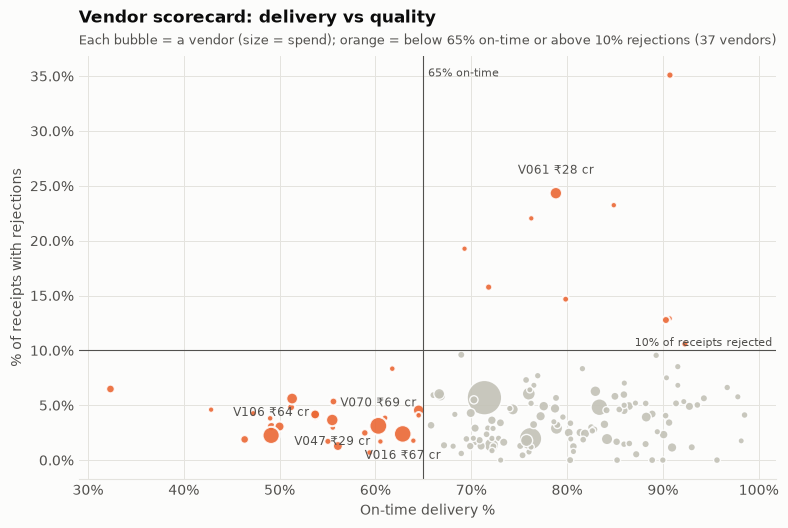

In [6]:
big = sc[sc.lines_due >= 30].copy()
watch = (big.otd_pct < 65) | (big.receipts_with_rejection_pct > 10)

fig, ax = plt.subplots(figsize=(9, 5.5))
sizes = 20 + big.spend_crore / big.spend_crore.max() * 600
ax.scatter(big.loc[~watch, "otd_pct"], big.loc[~watch, "receipts_with_rejection_pct"], s=sizes[~watch],
           color=MUTED, edgecolor="white", lw=1, alpha=0.9)
ax.scatter(big.loc[watch, "otd_pct"], big.loc[watch, "receipts_with_rejection_pct"], s=sizes[watch],
           color=SERIES[1], edgecolor="white", lw=1.5, alpha=0.9)
# Label the five largest watch-list vendors; offsets alternate above/below to avoid collisions
offsets = [(0, 14), (0, -18), (0, 14), (0, -18), (0, 14)]
for (_, v), off in zip(big[watch].nlargest(5, "spend_crore").sort_values("otd_pct").iterrows(), offsets):
    ax.annotate(f"{v.vendor_id} ₹{v.spend_crore:.0f} cr", (v.otd_pct, v.receipts_with_rejection_pct),
                xytext=off, textcoords="offset points", ha="center", color=INK_2, fontsize=8.5)
ax.axvline(65, color=INK_2, lw=0.8)
ax.axhline(10, color=INK_2, lw=0.8)
ax.text(65.5, ax.get_ylim()[1] * 0.97, "65% on-time", color=INK_2, fontsize=8, va="top")
ax.text(ax.get_xlim()[1], 10.4, "10% of receipts rejected ", color=INK_2, fontsize=8, ha="right")
ax.set_xlabel("On-time delivery %")
ax.set_ylabel("% of receipts with rejections")
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title("Vendor scorecard: delivery vs quality")
subtitle(ax, f"Each bubble = a vendor (size = spend); orange = below 65% on-time or above 10% rejections ({watch.sum()} vendors)")
save(fig, "16_vendor_scorecard")
print(f"Vendors on the watch list: {watch.sum()}, holding {big.loc[watch, 'spend_share_pct'].sum():.1f}% of spend")
big[watch].sort_values("spend_crore", ascending=False)[cols].head(15)

## 5. Monthly trends

,otd_pct,otif_pct,urgent_order_pct
year,,,
2023,70.81,62.35,9.92
2024,71.08,62.74,9.94
2025,71.02,62.54,9.63


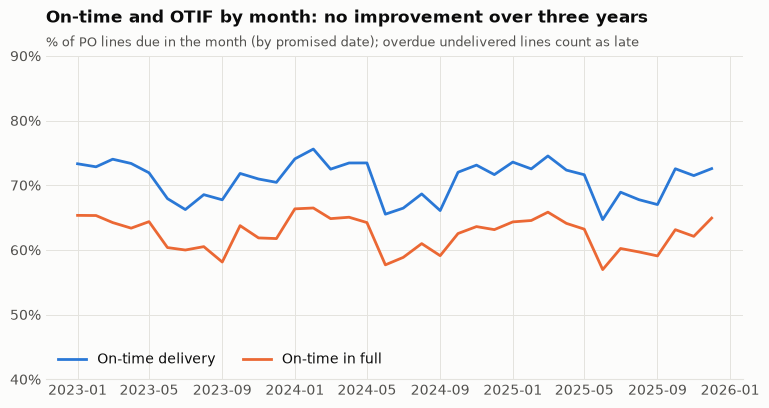

In [7]:
monthly = q("SELECT * FROM kpi_monthly ORDER BY month", dates=["month"])
monthly[monthly.columns.drop("month")] = monthly[monthly.columns.drop("month")].astype(float)

fig, ax = plt.subplots()
ax.plot(monthly.month, monthly.otd_pct, color=SERIES[0], label="On-time delivery")
ax.plot(monthly.month, monthly.otif_pct, color=SERIES[1], label="On-time in full")
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_ylim(40, 90)
ax.legend(loc="lower left", ncol=2)
ax.set_title("On-time and OTIF by month: no improvement over three years")
subtitle(ax, "% of PO lines due in the month (by promised date); overdue undelivered lines count as late")
save(fig, "17_otd_otif_monthly")
yearly = monthly.assign(year=monthly.month.dt.year).groupby("year").apply(
    lambda g: pd.Series({"otd_pct": np.average(g.otd_pct, weights=g.lines_due),
                         "otif_pct": np.average(g.otif_pct, weights=g.lines_due),
                         "urgent_order_pct": np.average(g.urgent_order_pct, weights=g.po_lines)}), include_groups=False)
yearly

## 6. KPIs by category

In [8]:
cat = q("SELECT * FROM kpi_category")
cat[cat.columns.drop("category")] = cat[cat.columns.drop("category")].astype(float)
cat.sort_values("spend_crore", ascending=False)

,category,po_lines,vendors,spend_crore,otd_pct,otif_pct,avg_lead_time_days,lead_time_sd_days,fill_rate_pct,rejection_rate_pct,urgent_order_pct,price_vs_standard_pct
6,Raw Materials,"11,087.00",30.00,895.60,73.35,63.41,14.35,6.70,98.52,0.41,10.56,6.80
1,Electrical & Electronics,"8,471.00",25.00,201.40,71.72,64.59,12.73,6.42,99.26,0.62,9.74,1.15
2,IT Hardware,"2,942.00",15.00,172.70,65.67,57.43,21.22,11.71,98.91,0.32,8.36,-0.93
5,Packaging,"7,346.00",22.00,90.67,66.71,59.56,13.00,9.90,98.92,0.34,9.80,1.39
3,MRO,"10,927.00",28.00,82.89,67.18,59.20,10.07,9.65,98.73,0.35,9.52,1.73
0,Chemicals,"5,004.00",15.00,79.97,75.10,66.17,11.99,5.57,99.13,0.25,10.15,1.94
4,Office Supplies,"4,194.00",15.00,16.81,79.41,69.41,5.26,5.15,99.41,0.47,9.47,2.27


## 7. Inventory KPIs by category

In [9]:
inv_items = q("SELECT * FROM kpi_inventory_items")
for c in ["standard_price", "avg_monthly_sales_6m", "months_of_cover", "closing_value", "excess_qty", "excess_value"]:
    inv_items[c] = inv_items[c].astype(float)
inv_cat = inv_items.groupby("category").agg(closing_value_cr=("closing_value", lambda x: x.sum() / 1e7),
                                            excess_value_cr=("excess_value", lambda x: x.sum() / 1e7),
                                            items_with_excess=("excess_value", lambda x: (x > 0).sum()))
inv_cat["excess_share_%"] = inv_cat.excess_value_cr / inv_cat.closing_value_cr * 100
print("Top 10 items by excess stock value")
display(inv_items.nlargest(10, "excess_value")[["item_id", "item_name", "category", "closing_qty",
                                                "avg_monthly_sales_6m", "months_of_cover", "excess_value"]])
inv_cat.sort_values("excess_value_cr", ascending=False)

Top 10 items by excess stock value


,item_id,item_name,category,closing_qty,avg_monthly_sales_6m,months_of_cover,excess_value
46,I0047,CR Coil 32mm,Raw Materials,715,12.00,59.58,"55,940,099.80"
53,I0054,Steel Billet 40mm,Raw Materials,1146,46.00,24.91,"50,895,530.70"
55,I0056,Steel Billet 32mm,Raw Materials,1416,59.67,23.73,"40,048,857.89"
133,I0134,TMT Bar 50mm,Raw Materials,611,21.00,29.10,"31,757,732.10"
52,I0053,MS Angle 25mm,Raw Materials,621,17.67,35.15,"30,641,489.00"
600,I0601,UPS Enterprise,IT Hardware,1873,36.33,51.55,"30,541,936.39"
79,I0080,Aluminium Sheet 50mm,Raw Materials,144478,"5,299.33",27.26,"27,600,329.13"
69,I0070,Wire Rod 40mm,Raw Materials,780,30.83,25.30,"27,061,757.45"
59,I0060,CR Coil 8mm,Raw Materials,259,6.67,38.85,"25,982,583.03"
12,I0013,CR Coil 50mm,Raw Materials,468,20.17,23.21,"25,430,570.87"


,closing_value_cr,excess_value_cr,items_with_excess,excess_share_%
category,,,,
Raw Materials,131.71,57.40,35,43.58
Electrical & Electronics,29.98,12.89,31,43.00
IT Hardware,26.44,11.76,13,44.48
Packaging,14.63,6.74,25,46.07
Chemicals,12.90,6.27,21,48.64
MRO,10.24,3.14,27,30.66
Office Supplies,2.64,1.13,22,43.00


## 8. Export

In [10]:
exports = {
    "kpi_summary": summary,
    "kpi_vendor_scorecard": sc,
    "kpi_category": cat,
    "kpi_monthly": monthly,
    "kpi_inventory_items": inv_items,
    "kpi_single_source_items": q("SELECT * FROM kpi_single_source_items ORDER BY spend_crore DESC"),
    "kpi_sql_vs_pandas_check": check,
}
for name, df in exports.items():
    df.to_csv(KPI_DIR / f"{name}.csv", index=False)
print("Exported:", ", ".join(f"{n}.csv ({len(df)} rows)" for n, df in exports.items()))

Exported: kpi_summary.csv (24 rows), kpi_vendor_scorecard.csv (150 rows), kpi_category.csv (7 rows), kpi_monthly.csv (36 rows), kpi_inventory_items.csv (800 rows), kpi_single_source_items.csv (151 rows), kpi_sql_vs_pandas_check.csv (24 rows)


## 9. Summary

Full interpretation: [`reports/kpi_report.md`](../reports/kpi_report.md).

- **Delivery is the main problem.** OTD is 71.0% and OTIF 62.6%, flat for three years, while the fill rate is 98.9%: vendors ship the quantity, but late.
- **37 vendors are on the watch list** (below 65% on-time or above 10% rejections). They hold 29% of spend; the largest are V070, V016 and V106.
- **Dependency:** V017 is 18.7% of total spend and 32% of Raw Materials.
- **Buying behaviour:** bulk savings are ₹104 crore (13.1% discount); the urgent-order premium is ₹5.2 crore.
- **Inventory:** ₹99 crore (43.5% of stock) sits above 6 months of cover; turnover is 2.4×.
- **Checks:** all 24 KPIs match between SQL and pandas; stock reconciles exactly for 73% of items, and the gaps trace to cleaning losses.